Import libraries and load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/Crop_recommendationV2_noisy.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (2200, 23)


,N,P,K,temperature,humidity,ph,rainfall,label,soil_moisture,soil_type,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
0,92,39,43,21.550704,84.564613,6.512764,190.170504,rice,29.446064,2,...,3.121395,4,11.743910,57.607308,188.194958,1,2.719614,3,95.649985,1.193293
1,79,57,37,21.538280,83.044875,6.964714,219.161423,rice,12.851183,3,...,2.142021,4,16.797101,74.736879,70.963629,1,4.714427,2,77.265694,1.752672
2,64,55,39,23.491878,81.684115,7.871646,260.791775,rice,29.363913,2,...,1.474974,1,12.654395,1.034478,191.976077,1,30.431736,2,18.192168,3.035541
3,79,38,52,26.660402,78.985342,7.058356,240.015806,rice,26.207732,3,...,8.393907,1,10.864360,24.091888,55.761388,3,10.861071,3,82.818720,1.273341
4,67,47,41,20.676929,85.389654,7.653656,261.654779,rice,28.236236,2,...,5.202285,3,13.852910,38.811481,185.259702,2,47.190777,3,25.466499,2.578671


Inspect columns, data types, missing values and duplicates

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label', 'soil_moisture', 'soil_type', 'sunlight_exposure', 'wind_speed', 'co2_concentration', 'organic_matter', 'irrigation_frequency', 'crop_density', 'pest_pressure', 'fertilizer_usage', 'growth_stage', 'urban_area_proximity', 'water_source_type', 'frost_risk', 'water_usage_efficiency']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       2200 non-null   int64  
 1   P                       2200 non-null   int64  
 2   K                       2200 non-null   int64  
 3   temperature             2200 non-null   float64
 4   humidity                2200 non-null   float64
 5   ph                      2200 non-null   float64
 6   rainfall                2200 non-null   float64
 7   label                  

Summary statistics

In [ ]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.408182,37.174083,0.000000,20.000000,38.000000,85.000000,140.000000
P,2200.0,53.490909,33.312744,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.303182,50.655758,5.000000,20.000000,32.500000,51.000000,205.000000
temperature,2200.0,25.608268,5.106573,8.825675,22.607507,25.587514,28.632921,43.675493
humidity,2200.0,71.396011,22.402283,14.258040,59.671085,79.145393,88.880953,99.981876
ph,2200.0,6.466274,0.782864,3.504752,5.954098,6.424807,6.922333,9.935091
rainfall,2200.0,103.695575,55.188002,20.211267,63.747124,94.750579,127.251776,298.560117
soil_moisture,2200.0,20.151388,5.793720,10.024260,15.179949,20.088481,25.255146,29.997860
soil_type,2200.0,1.991364,0.812263,1.000000,1.000000,2.000000,3.000000,3.000000
sunlight_exposure,2200.0,8.570609,1.999382,5.000710,6.904620,8.609968,10.220394,11.991041


Inspect the crop labels

In [ ]:
print("Number of unique crops:", df["label"].nunique())

print("\nCrop names:")
print(sorted(df["label"].unique()))

print("\nSamples per crop:")
display(df["label"].value_counts().sort_index())


Number of unique crops: 22

Crop names:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']

Samples per crop:


,count
label,
apple,92
banana,97
blackgram,103
chickpea,95
coconut,104
coffee,94
cotton,102
grapes,100
jute,106


Visualize the number of samples per crop

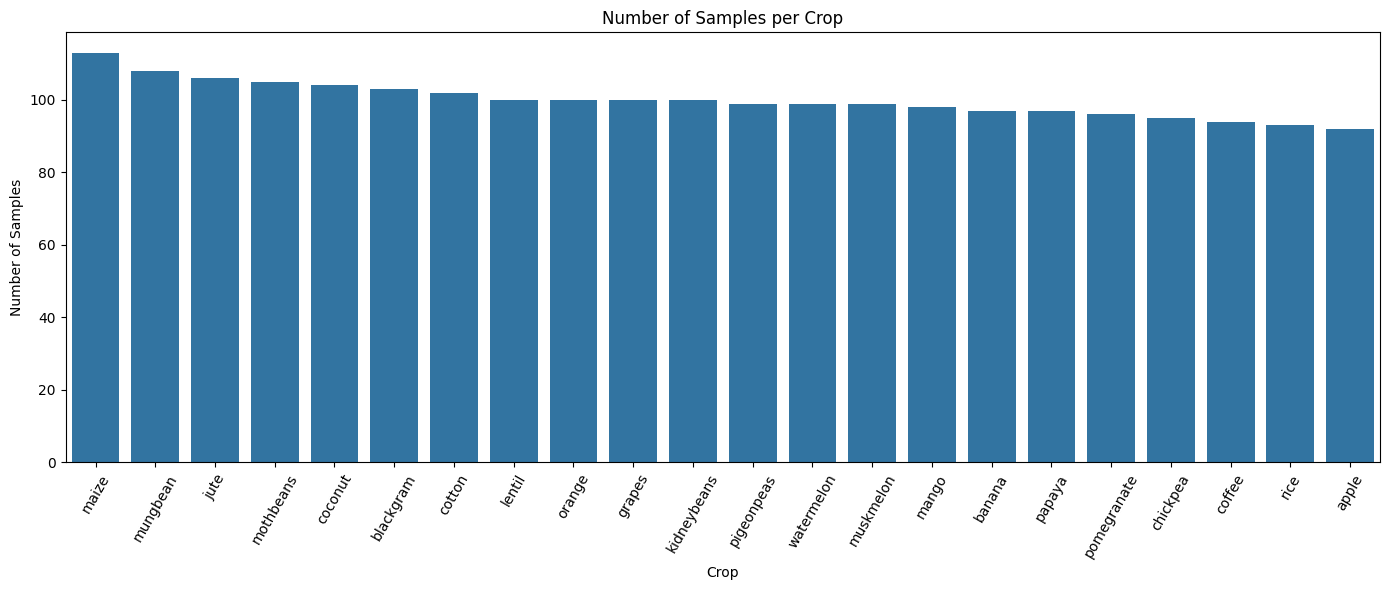

In [ ]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("Number of Samples per Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


Examine the seven core features

In [ ]:
core_features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

display(df[core_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.408182,37.174083,0.000000,20.000000,38.000000,85.000000,140.000000
P,2200.0,53.490909,33.312744,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.303182,50.655758,5.000000,20.000000,32.500000,51.000000,205.000000
temperature,2200.0,25.608268,5.106573,8.825675,22.607507,25.587514,28.632921,43.675493
humidity,2200.0,71.396011,22.402283,14.258040,59.671085,79.145393,88.880953,99.981876
ph,2200.0,6.466274,0.782864,3.504752,5.954098,6.424807,6.922333,9.935091
rainfall,2200.0,103.695575,55.188002,20.211267,63.747124,94.750579,127.251776,298.560117


Visualize feature distributions

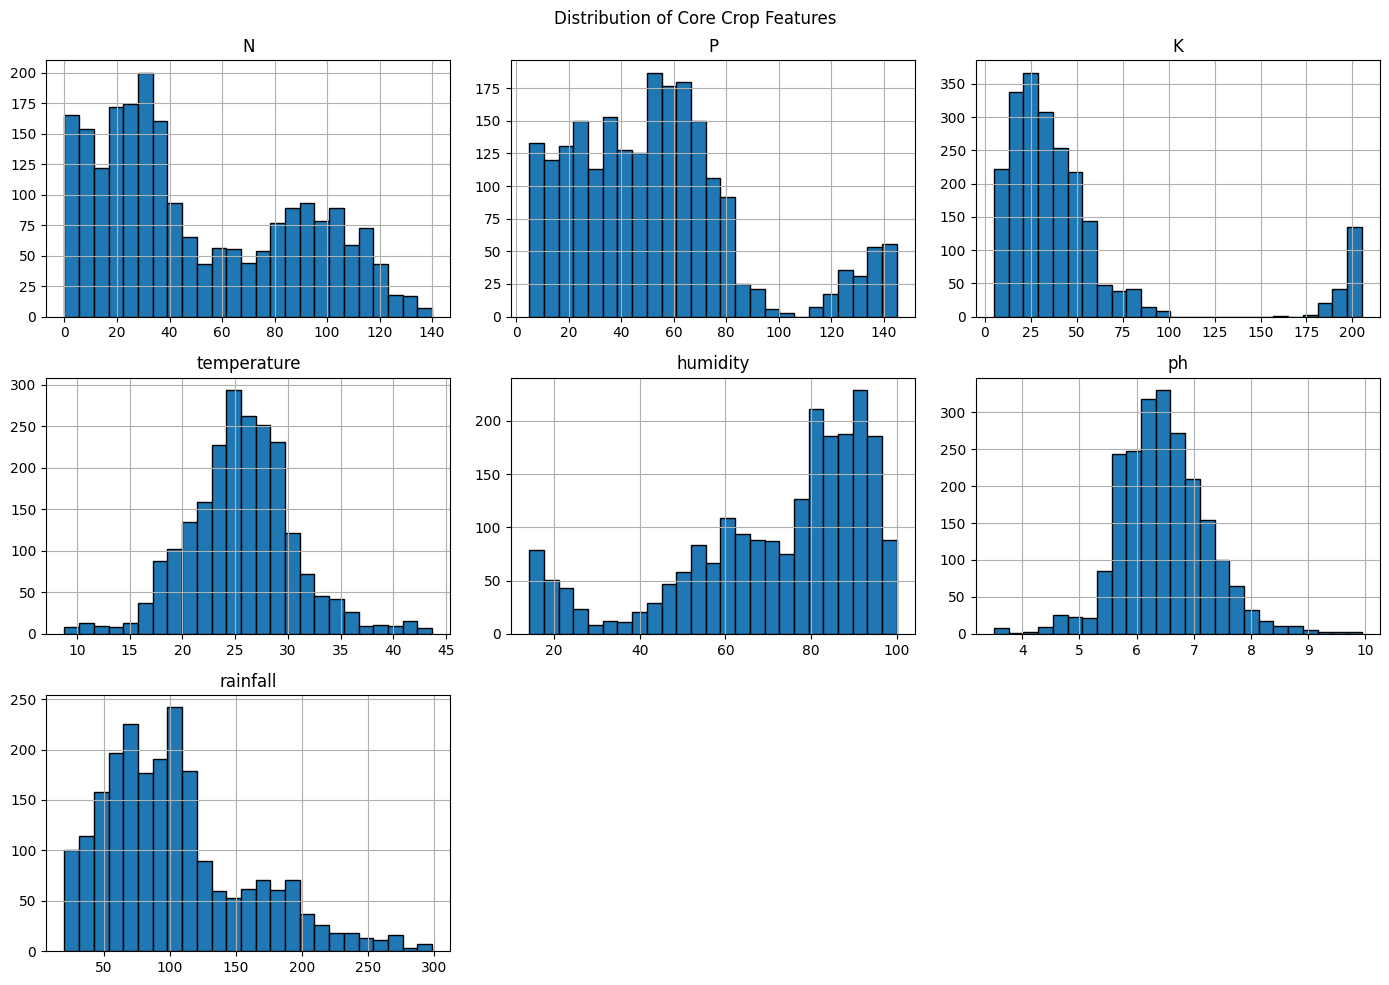

In [ ]:
df[core_features].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Core Crop Features")
plt.tight_layout()
plt.show()

Define the features and target

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

X = df.drop("label", axis=1)
y = df["label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2200, 22)
Target shape: (2200,)


Split the dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (1760, 22)
Testing set shape: (440, 22)


Train the Random Forest model

In [ ]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Evaluate model accuracy

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9136

Classification Report:
              precision    recall  f1-score   support

       apple       0.89      0.94      0.92        18
      banana       0.95      1.00      0.97        19
   blackgram       1.00      0.85      0.92        20
    chickpea       1.00      1.00      1.00        19
     coconut       1.00      0.90      0.95        21
      coffee       0.95      0.95      0.95        19
      cotton       0.82      0.90      0.86        20
      grapes       0.90      0.95      0.93        20
        jute       0.72      0.86      0.78        21
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.90      0.95      0.93        20
       maize       1.00      0.83      0.90        23
       mango       0.95      1.00      0.98        20
   mothbeans       1.00      0.86      0.92        21
    mungbean       0.92      1.00      0.96        22
   muskmelon       0.86      0.95      0.90        20
      orange       0.86      0.95      0

Plot the confusion matrix

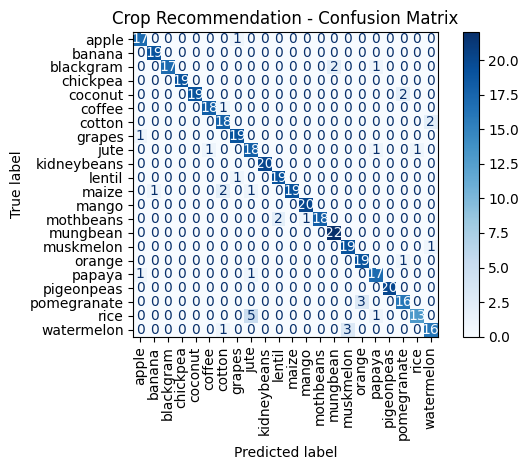

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("Crop Recommendation - Confusion Matrix")
plt.tight_layout()
plt.show()

Feature Importance Analysis

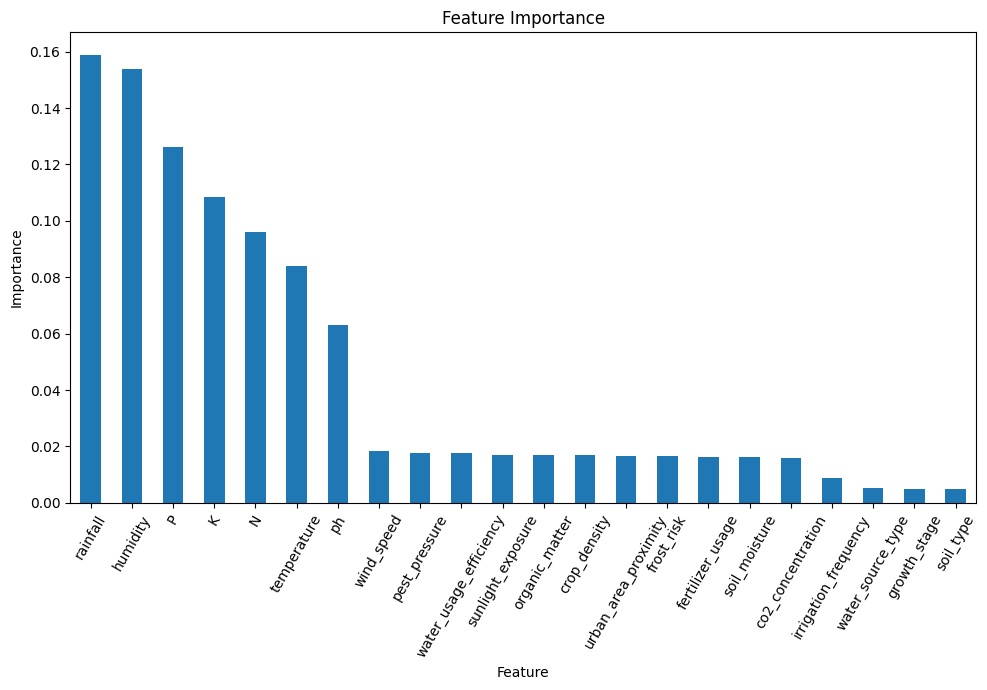

,0
rainfall,0.158922
humidity,0.153902
P,0.126060
K,0.108590
N,0.096041
temperature,0.083872
ph,0.063040
wind_speed,0.018251
pest_pressure,0.017688
water_usage_efficiency,0.017639


In [ ]:
importances = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
importances.plot(kind="bar")
plt.title("Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

display(importances)

Save the trained model

In [ ]:
import joblib

joblib.dump(model, "crop_model.joblib")

print("Model saved successfully!")

Model saved successfully!


loading the saved file
after running this cell it is necessery to upload the files if runtime is restarted

In [ ]:
import joblib

model = joblib.load("crop_model.joblib")

print("Model loaded successfully!")

Model loaded successfully!


Make a prediction ( here the input data wat taken from first line of dataset )

In [ ]:
import pandas as pd

sample = X.iloc[[0]].copy()

prediction = model.predict(sample)

print("Recommended crop:", prediction[0])

Recommended crop: jute


Check the prediction

In [ ]:
actual_crop = df.iloc[0]["label"]

print("Actual crop:", actual_crop)
print("Predicted crop:", prediction[0])

Actual crop: rice
Predicted crop: jute


Try a test-set example

In [ ]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Predicted crop:", prediction[0])
print("Actual crop:", y_test.iloc[0])

Predicted crop: orange
Actual crop: orange


the current model is trained on 22 features making and training an model on 7 features

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

core_features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

X_core = df[core_features]
y = df["label"]

X_train_core, X_test_core, y_train_core, y_test_core = train_test_split(
    X_core,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

crop_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

crop_model.fit(X_train_core, y_train_core)

print("Seven-feature model trained successfully!")

Seven-feature model trained successfully!


Enter own field measurements

In [ ]:
import pandas as pd

field_data = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25.0,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 200.0
}])

predicted_crop = crop_model.predict(field_data)[0]

print("Recommended crop:", predicted_crop)

Recommended crop: jute


Finding Accuracy

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

core_predictions = crop_model.predict(X_test_core)

print("Accuracy:", accuracy_score(y_test_core, core_predictions))
print(classification_report(y_test_core, core_predictions))

Accuracy: 0.9136363636363637
              precision    recall  f1-score   support

       apple       0.89      0.94      0.92        18
      banana       0.95      1.00      0.97        19
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        19
     coconut       1.00      0.90      0.95        21
      coffee       0.94      0.89      0.92        19
      cotton       0.78      0.90      0.84        20
      grapes       0.90      0.95      0.93        20
        jute       0.75      0.86      0.80        21
 kidneybeans       1.00      0.95      0.97        20
      lentil       0.95      0.95      0.95        20
       maize       1.00      0.83      0.90        23
       mango       0.95      1.00      0.98        20
   mothbeans       0.90      0.90      0.90        21
    mungbean       0.92      1.00      0.96        22
   muskmelon       0.90      0.95      0.93        20
      orange       0.86      0.95      0.90        2

In [ ]:
!pip install -q shap
from google.colab import files
from export_utils import export_module
export_module("crop", crop_model, X_train_core, y_train_core, X_test_core, y_test_core,
              trained_on="Crop_recommendationV2_noisy.csv")
!zip -rq crop_export.zip models/crop
files.download("crop_export.zip")

dashboard config block: {"metrics": {"accuracy": 0.9136, "top3": 0.975, "macro_f1": 0.9136}, "importance": {"Relative humidity": 0.1974, "Nitrogen": 0.1907, "Rainfall": 0.1866, "Phosphorus": 0.1648, "Potassium": 0.121, "Temperature": 0.09, "Soil pH": 0.0496}}
Exported crop -> models/crop  |  {'accuracy': 0.9136, 'macro_f1': 0.9136, 'top3_accuracy': 0.975, 'n_train': 1760, 'n_test': 440}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
print(json.load(open("models/crop/metadata.json"))["importance"][:3])

[{'feature': 'humidity', 'importance': 0.1974}, {'feature': 'N', 'importance': 0.1907}, {'feature': 'rainfall', 'importance': 0.1866}]
